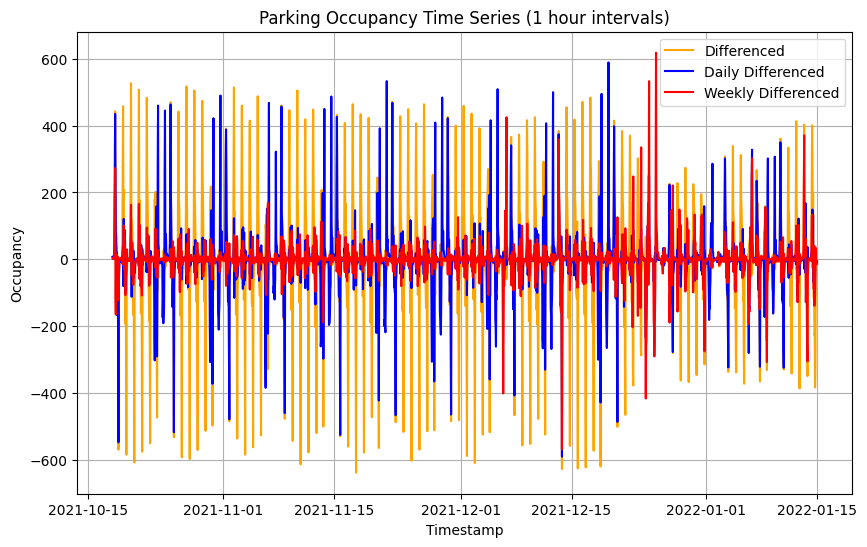

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller

# Read the CSV file into a pandas DataFrame with correct delimiter
df = pd.read_csv('../preprocess/parking_time_series_filtered_1_hour.csv', delimiter=',')

# Convert timestamp column to DateTime format
df['Time'] = pd.to_datetime(df['Time'])

# Set timestamp column as index (assuming it represents time)
df.set_index('Time', inplace=True)

# Regular differencing
df['Parkings_diff'] = df['Parkings'].diff()

# Daily seasonal differencing (24 hours)
df['Parkings_diff_daily'] = df['Parkings_diff'].diff(24)

# Weekly seasonal differencing (7 days * 24 hours)
df['Parkings_diff_weekly'] = df['Parkings_diff'].diff(24 * 7)

# Drop NaNs introduced by differencing
df.dropna(subset=['Parkings_diff_daily', 'Parkings_diff_weekly'], inplace=True)

# Plot the time series data
plt.figure(figsize=(10, 6))
plt.plot(df.index, df['Parkings_diff'], color='orange', label='Differenced')
plt.plot(df.index, df['Parkings_diff_daily'], color='blue', label='Daily Differenced')
plt.plot(df.index, df['Parkings_diff_weekly'], color='red', label='Weekly Differenced')
plt.title('Parking Occupancy Time Series (1 hour intervals)')
plt.xlabel('Timestamp')
plt.ylabel('Occupancy')
plt.legend()
plt.grid(True)
plt.show()

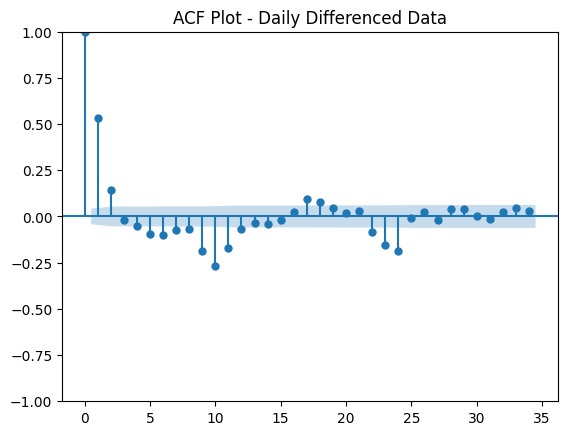

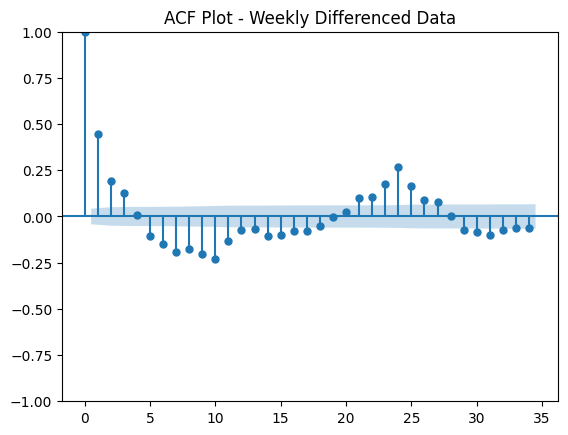

In [6]:

# Compute and plot autocorrelation function (ACF)
#plot_acf(df['Parkings_diff'], lags=168 , alpha=0.05, marker='').set_figwidth(9)
#plt.title('Autocorrelation Function (ACF)')
#plt.xlabel('Lag')
#plt.ylabel('Autocorrelation')
#plt.grid(True)
#plt.show()

plot_acf(df['Parkings_diff_daily'])
plt.title('ACF Plot - Daily Differenced Data')
plt.show()

plot_acf(df['Parkings_diff_weekly'])
plt.title('ACF Plot - Weekly Differenced Data')
plt.show()


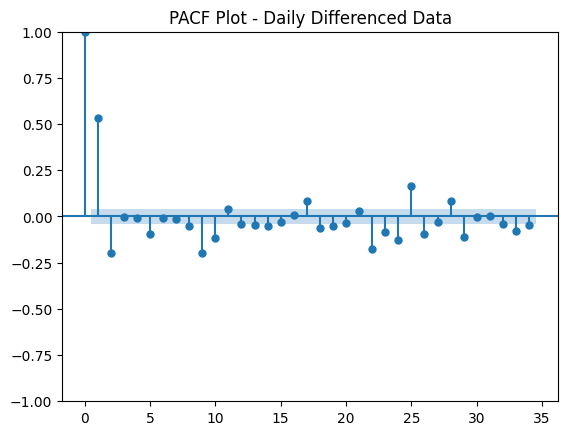

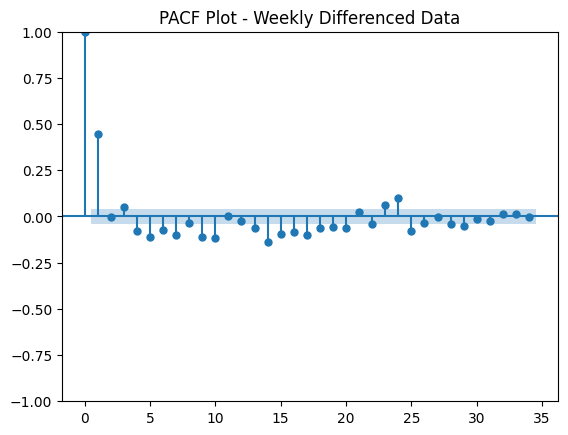

In [7]:



# Plot the partial autocorrelation function (PACF)
#plot_pacf(df['Parkings_diff'], lags=168, marker='').set_figwidth(10)
#plt.title('Partial Autocorrelation Function (PACF)')
#plt.xlabel('Lag')
#plt.ylabel('Partial Autocorrelation')
#plt.grid(True)
#plt.show()


plot_pacf(df['Parkings_diff_daily'])
plt.title('PACF Plot - Daily Differenced Data')
plt.show()

plot_pacf(df['Parkings_diff_weekly'])
plt.title('PACF Plot - Weekly Differenced Data')
plt.show()


ADF Statistic: -12.161676175882018
p-value: 1.4887137611819304e-22


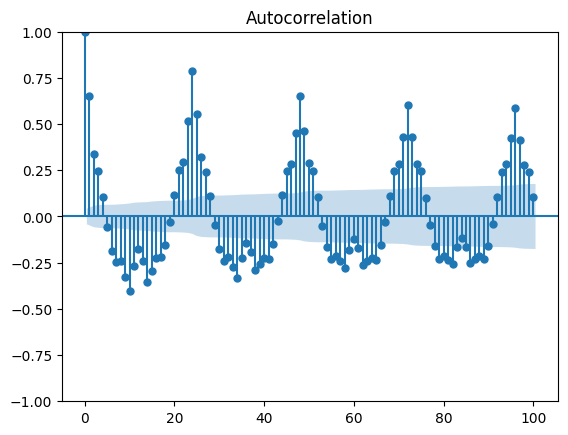

The time series is stationary.


In [11]:

# Perform Augmented Dickey-Fuller test to check stationarity
result = adfuller(df['Parkings_diff'])

# Print the test statistic and p-value
print('ADF Statistic:', result[0])
print('p-value:', result[1])

# Plot ACF to visualize autocorrelation
plot_acf(df['Parkings_diff'], lags=100)
plt.show()

# Interpret the result
if result[1] <= 0.05:
    print("The time series is stationary.")
else:
    print("The time series is not stationary.")

In [9]:


# Check for stationarity using the Augmented Dickey-Fuller (ADF) test
result = adfuller(df['Parkings_diff'])
print('ADF Statistic:', result[0])
print('p-value:', result[1])

ADF Statistic: -12.161676175882018
p-value: 1.4887137611819304e-22
